# Заняття 12 · Demo 3 — early fusion на реальних парах: 4-канальний тензор і хірургія першого conv

Дані — реальні вирівняні пари RGB + LWIR (`rgbt12.py`, завантаження: `python tools/fetch_rgbt.py`, ≈ 1,3 ГБ):

- **LLVIP** (Jia et al., ICCVW 2021) — 1280×1024, пари вирівняні апаратно; 24 нічні сцени і 2 денні (25 і 26).
  Спліт авторів — за сценами: train — сцени 01–18 і 25, test — 19–24 і 26. Беремо кожен 6-й кадр train і кожен 4-й test.
- **FLIR-aligned** (Zhang et al., ICIP 2020) — 640×512, пари FLIR ADAS v1, вирівняні вручну, день і ніч.
  Спліт авторів `align_train` / `align_validation` — різні поїздки.

Ціль — люди (person). Кадри зменшено до 160×128, щоб навчання вкладалося в хвилини на CPU. Детектор — CenterNet-подібна
heatmap-мережа (~57 тис. параметрів); детекція правильна, якщо центр лежить у радіусі max(2 px, 0.2·h) від центру боксу;
люди нижчі за 6 px на цій сітці — зона ігнору. Без даних ноутбук переходить на процедурну синтетику 64×64.

1. Датасет: умови, поріг день / ніч, статистики T — свої для кожного датасету.
2. Хірургія першого conv: zero / mean / random init, збереження функції, вартість у MAC.
3. Fine-tune 4-ch з RGB-ваг проти навчання з нуля.
4. RGB-only, T-only, early 4-ch, early + modality dropout: AP за умовами.
5. Ultralytics 8.4: що насправді відбувається з 4-канальним входом (перевірка коду, якщо пакет встановлено).

Перший запуск навчає моделі (~5 хв кожна на 10-ядерному CPU, усе Demo 3 — ~25 хв) і кладе ваги в `_cache12/`; Demo 4 бере їх звідти.

In [1]:
%matplotlib inline
import sys, copy, time, numpy as np, matplotlib.pyplot as plt, torch
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import fuse12 as F, rgbt12 as R, panels as P
plt.rcParams['figure.dpi'] = 90
torch.manual_seed(0)
data = F.load_data()
REAL = isinstance(data, F.RealData)

train 4070 пар (2005 LLVIP, 2065 FLIR), test 1879 пар; людей train 9310, test 5904 (+319 у зоні ігнору); 34 с


## 1. Датасет
Кадри test з розміткою: верхній ряд — RGB, нижній — T (8 біт після AGC камери, як їх віддають обидва датасети).

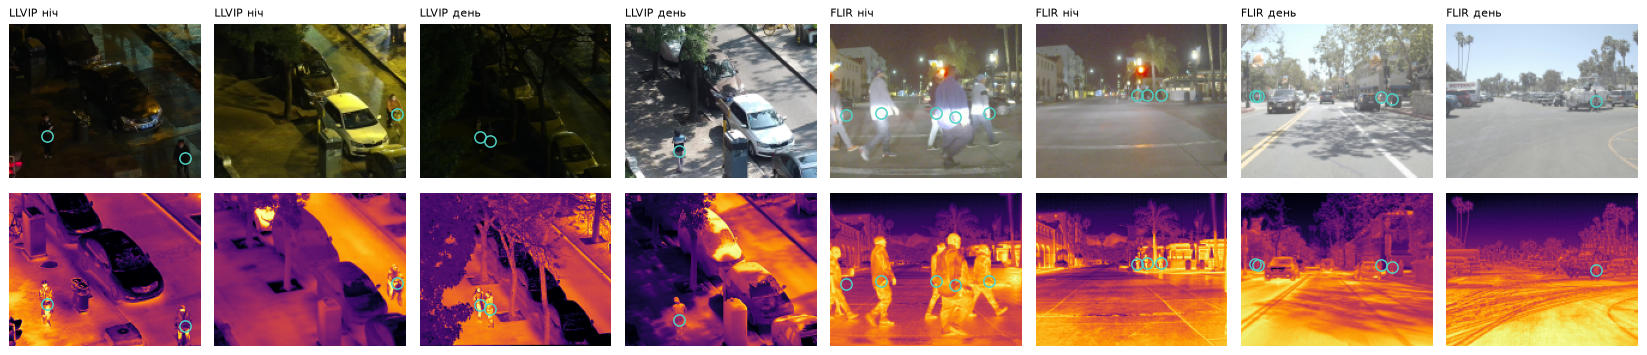

In [2]:
def show(i, ax_rgb, ax_t):
    x = data.raw_te[i].astype(np.float32) / (255 if REAL else 1)
    ax_rgb.imshow(np.clip(np.transpose(x[:3], (1, 2, 0)), 0, 1)); ax_t.imshow(x[3], cmap='inferno')
    c = data.Cte[i]
    for a in (ax_rgb, ax_t):
        a.plot(c[:, 0], c[:, 1], 'o', mfc='none', mec='#4FD1C5', ms=9, mew=1.2); a.set_axis_off()
    ax_rgb.set_title(F.label(data.cond[i]), fontsize=9, loc='left')

rng = np.random.default_rng(3)
pick = [rng.choice(np.where((data.cond == c) & np.array([len(g) > 0 for g in data.Cte]))[0]) for c in data.conds for _ in range(2)]
fig, ax = plt.subplots(2, len(pick), figsize=(2.3 * len(pick), 4.2))
for j, i in enumerate(pick):
    show(i, ax[0, j], ax[1, j])
plt.tight_layout(); plt.show()

### Поріг день / ніч
FLIR не має мітки часу доби в розмітці. Середня яскравість кадру — погана ознака: уночі її піднімають ліхтарі, фари й
автоекспозиція, а чорні поля вирівнювання опускають. Беремо медіану яскравості **неба** (верхня третина кадру): гістограма
має провал, і поріг `R.DAY_SKY` ставимо в ньому. LLVIP ділимо за сценою: 2 денні сцени (25 — train, 26 — test), решта — ніч,
зокрема освітлені вулиці. Денного LLVIP у test — одна сцена, тож CI для неї будуть широкі.

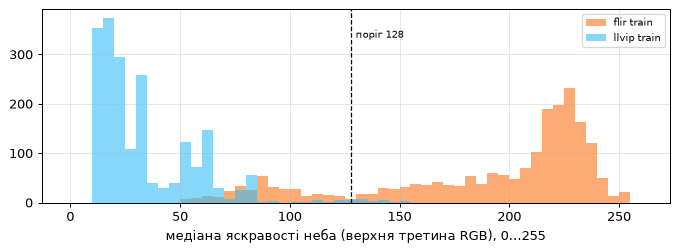

LLVIP ніч : train  1934 кадрів, test   733 кадрів, людей у test  1840
LLVIP день: train    71 кадрів, test   133 кадрів, людей у test   266
FLIR ніч  : train   332 кадрів, test   309 кадрів, людей у test  1117
FLIR день : train  1733 кадрів, test   704 кадрів, людей у test  2681
LLVIP test, медіана яскравості неба за сценами: {'19': 35, '20': 17, '21': 43, '22': 40, '23': 17, '24': 11, '26': 37}


In [3]:
if REAL:
    fig, ax = plt.subplots(figsize=(9, 2.8))
    for src, c in (('flir', P.C_T), ('llvip', P.C_RGB)):
        ax.hist(data.luma_tr[data.src_tr == src], bins=52, range=(0, 260), alpha=0.6, color=c, label=f'{src} train')
    ax.axvline(R.DAY_SKY, color='k', ls='--', lw=1); ax.text(R.DAY_SKY + 2, ax.get_ylim()[1] * 0.85, f'поріг {R.DAY_SKY:.0f}', fontsize=8)
    ax.set_xlabel('медіана яскравості неба (верхня третина RGB), 0…255'); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
    for c in data.conds:
        n_tr, n_te = (data.cond_tr == c).sum(), (data.cond == c).sum()
        ppl = sum(len(data.Cte[i]) for i in np.where(data.cond == c)[0])
        print(f'{F.label(c):10s}: train {n_tr:5d} кадрів, test {n_te:5d} кадрів, людей у test {ppl:5d}')
    import collections
    sc = collections.defaultdict(list)
    for p, l in zip(data.pairs_te, data.luma):
        if p['src'] == 'llvip':
            sc[p['scene']].append(l)
    print('LLVIP test, медіана яскравості неба за сценами:', {k: int(np.median(v)) for k, v in sorted(sc.items())})

In [4]:
print('статистики train (0…1), канали R, G, B, T:  mean', np.round(data.mu, 3), ' std', np.round(data.sd, 3))
if REAL:
    for src in ('llvip', 'flir'):
        Xs = data.raw_te[data.src_te == src][:400, 3].astype(np.float32) / 255
        fm = Xs.mean((1, 2))
        print(f'T {src:5s}: mean {Xs.mean():.3f}, std {Xs.std():.3f}; середнє кадру гуляє {fm.min():.2f}…{fm.max():.2f} — AGC кожного кадру свій')
print('ImageNet RGB mean (0.485, 0.456, 0.406) — для T-каналу такої константи немає: рахуємо на своєму train')

статистики train (0…1), канали R, G, B, T:  mean [0.416 0.416 0.382 0.41 ]  std [0.292 0.302 0.326 0.254]
T llvip: mean 0.340, std 0.208; середнє кадру гуляє 0.19…0.43 — AGC кожного кадру свій
T flir : mean 0.530, std 0.258; середнє кадру гуляє 0.41…0.64 — AGC кожного кадру свій
ImageNet RGB mean (0.485, 0.456, 0.406) — для T-каналу такої константи немає: рахуємо на своєму train


**Що бачимо.** Два датасети — два різні AGC: середнє і розкид T-каналу різні, а середнє кадру гуляє від кадру до кадру.
Мережа вчиться на суміші доменів; на новій камері з іншим AGC вона побачить третій домен (Demo 1, розділ 5).

## 2. Хірургія першого conv
Слайд «Fusion · early». Беремо навчену RGB-модель і розширюємо stem 3 → 4 канали трьома способами.
`zero` — мережа на першому кроці рахує **рівно** те саме, що RGB-модель (функцію збережено), T-канал вмикається градієнтом.

In [5]:
rgb = F.get_model('RGB', data)
x = data.Xte[:256].float()
for init in ('zero', 'mean', 'random'):
    m = copy.deepcopy(rgb); m.channels = [0, 1, 2, 3]
    m.enc.stem[0] = F.widen_first_conv(m.enc.stem[0], 1, init, seed=0)
    m.eval()
    with torch.no_grad():
        d = (m(x) - rgb(x)).abs().max().item()
    print(f'init = {init:6s}: max |вихід 4-ch − вихід RGB| = {d:.2e}   ' + ('← функцію збережено' if d < 1e-5 else ''))

RGB              — навчено за 307.3 с, параметрів 57,065


init = zero  : max |вихід 4-ch − вихід RGB| = 0.00e+00   ← функцію збережено


init = mean  : max |вихід 4-ch − вихід RGB| = 4.21e+00   


init = random: max |вихід 4-ch − вихід RGB| = 5.38e+00   


In [6]:
H, W = data.size
print('вартість першого шару (MAC):')
print(f'  наш stem 3×3, {W}×{H}, stride 1, → 8:   3-ch {F.conv_macs(3, 8, 3, H, W, 1) / 1e6:5.2f} M, 4-ch {F.conv_macs(4, 8, 3, H, W, 1) / 1e6:5.2f} M')
print(f'  YOLOv8n stem 3×3, 640², stride 2, → 16: 3-ch {F.conv_macs(3, 16, 3, 640, 640, 2) / 1e6:5.1f} M, '
      f'4-ch {F.conv_macs(4, 16, 3, 640, 640, 2) / 1e6:5.1f} M  (+⅓ лише першого шару; уся YOLOv8n — 8.86 → 8.89 GFLOPs)')

вартість першого шару (MAC):
  наш stem 3×3, 160×128, stride 1, → 8:   3-ch  4.42 M, 4-ch  5.90 M
  YOLOv8n stem 3×3, 640², stride 2, → 16: 3-ch  44.2 M, 4-ch  59.0 M  (+⅓ лише першого шару; уся YOLOv8n — 8.86 → 8.89 GFLOPs)


## 3. Fine-tune 4-ch з RGB-ваг: 1 епоха
Чесне порівняння: однаковий бюджет кроків, однакова LR. Де опиняється валідаційний loss і AP після однієї епохи?

zero   : val loss 2.285, AP all 0.241, LLVIP ніч 0.401, LLVIP день 0.405, FLIR ніч 0.183, FLIR день 0.214  (33 с)


mean   : val loss 1.764, AP all 0.269, LLVIP ніч 0.432, LLVIP день 0.456, FLIR ніч 0.239, FLIR день 0.191  (32 с)


random : val loss 1.662, AP all 0.283, LLVIP ніч 0.444, LLVIP день 0.441, FLIR ніч 0.217, FLIR день 0.196  (33 с)


з нуля : val loss 2.443, AP all 0.096, LLVIP ніч 0.187, LLVIP день 0.086, FLIR ніч 0.109, FLIR день 0.029  (33 с)


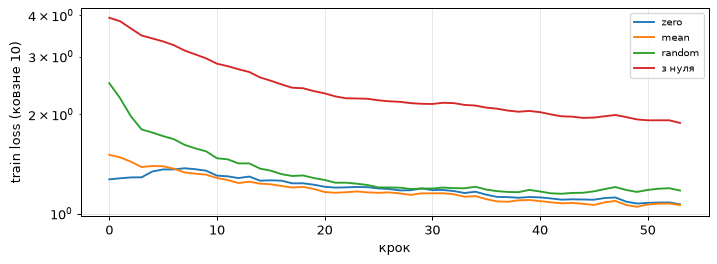

In [7]:
def finetune(init, epochs=1):
    if init == 'з нуля':
        m = F.make_model('early 4-ch', data)
    else:
        m = copy.deepcopy(rgb); m.channels = [0, 1, 2, 3]
        m.enc.stem[0] = F.widen_first_conv(m.enc.stem[0], 1, init, seed=0)
    hist = F.train(m, data, epochs=epochs, lr=2e-3)
    res, _ = F.evaluate({'m': m}, data, late=False)
    return m, hist, res['m']

ft = {}
for init in ('zero', 'mean', 'random', 'з нуля'):
    t0 = time.time(); m, h, r = finetune(init)
    ft[init] = (h, r)
    print(f'{init:7s}: val loss {F.val_loss(m, data):.3f}, AP all {r["all"]:.3f}, ' +
          ', '.join(f'{F.label(c)} {r[c]:.3f}' for c in data.conds) + f'  ({time.time() - t0:.0f} с)')
fig, ax = plt.subplots(figsize=(9, 3))
for k, (h, _) in ft.items():
    ax.plot(np.convolve(h, np.ones(10) / 10, mode='valid'), label=k)
ax.set_yscale('log'); ax.set_xlabel('крок'); ax.set_ylabel('train loss (ковзне 10)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

**Що бачимо.** За однаковий бюджет (1 епоха) старт з RGB-ваг дає кращий AP, ніж навчання з нуля: перенесені RGB-ознаки
вже вміють знаходити людей. Різниця між `zero`, `mean` і `random` для T-каналу мала (порівняйте з CI у Demo 4), але лише
`zero` гарантує, що в нулі навчання мережа рахує те саме, що RGB-baseline; `random` — дефолт Ultralytics для 4-го каналу —
на старті додає на вхід шум.

## 4. Чотири моделі, повне навчання

In [8]:
models = {k: F.get_model(k, data) for k in ('RGB', 'T', 'early 4-ch', 'early + dropout')}
res, dets = F.evaluate(models, data, late=False)
print(f'{"модель":16s} ' + ' '.join(f'{F.label(c):>11s}' for c in data.conds) + f' {"all":>7s}')
for k, v in res.items():
    print(f'{k:16s} ' + ' '.join(f'{v[c]:11.3f}' for c in data.conds) + f' {v["all"]:7.3f}')

RGB              — з кешу real1_RGB.pt


T                — навчено за 298.6 с, параметрів 56,921


early 4-ch       — навчено за 300.7 с, параметрів 57,137


early + dropout  — навчено за 300.6 с, параметрів 57,137


модель             LLVIP ніч  LLVIP день    FLIR ніч   FLIR день     all
RGB                    0.256       0.363       0.123       0.206   0.174
T                      0.642       0.544       0.357       0.143   0.369
early 4-ch             0.683       0.592       0.383       0.195   0.420
early + dropout        0.648       0.624       0.423       0.214   0.415


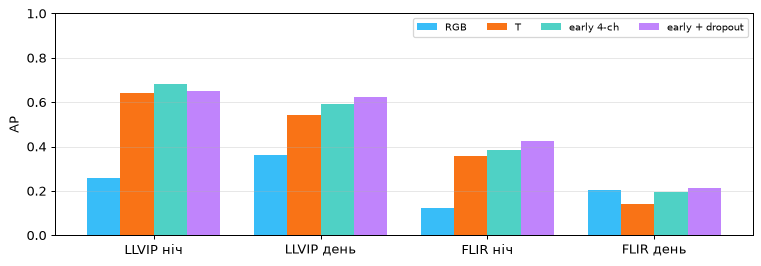

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.2))
w = 0.2; nc = len(data.conds)
for j, (k, v) in enumerate(res.items()):  # noqa
    ax.bar(np.arange(nc) + (j - 1.5) * w, [v[c] for c in data.conds], w, label=k, color=(P.C_RGB, P.C_T, P.C_F, '#C084FC')[j])
ax.set_xticks(range(nc)); ax.set_xticklabels([F.label(c) for c in data.conds]); ax.set_ylabel('AP'); ax.set_ylim(0, 1)
ax.legend(fontsize=8, ncol=4); ax.grid(alpha=0.3, axis='y'); plt.show()

**Що бачимо.** Уночі T сильніший за RGB у 2–3 рази, і early 4-ch додає до нього ще кілька сотих. На денних кадрах FLIR
T-only — найслабша модель (низький тепловий контраст людини вдень, Demo 1, розділ 3), а early не перевершує RGB-only:
fusion не стає кращим автоматично, приріст залежить від умови. Чи є він статистично — парний bootstrap у Demo 4.
Абсолютні AP невисокі: мала мережа і сітка 160×128, де люди FLIR — 6–20 px. Порівнюємо моделі між собою, а не з SOTA.

In [10]:
# modality dropout: ціна на повному вході і виграш при відмові T (FFC, збій ядра) або RGB (засвіт, ніч без підсвітки)
for drop in (None, 't', 'rgb'):
    r, _ = F.evaluate({k: models[k] for k in ('early 4-ch', 'early + dropout')}, data, drop=drop, late=False)
    print(f'{"повний вхід" if drop is None else ("T = 0" if drop == "t" else "RGB = 0"):12s}: ' +
          ', '.join(f'{k} {v["all"]:.3f}' for k, v in r.items()))

повний вхід : early 4-ch 0.420, early + dropout 0.415


T = 0       : early 4-ch 0.018, early + dropout 0.203


RGB = 0     : early 4-ch 0.266, early + dropout 0.368


Early без dropout при T = 0 майже повністю «сліпне» — значно нижче за окрему RGB-модель, хоча RGB-канали на місці:
мережа ніколи не бачила входу без T. З modality dropout вона при T = 0 тримається на рівні RGB-only і вище, а на повному
вході майже нічого не втрачає.

## 5. Ultralytics 8.4 і 4-канальний вхід
Перевіряємо встановлений пакет, а не документацію. Якщо `ultralytics` не встановлено — клітинка лише друкує, що пропущено.
4-сторінковий TIFF збираємо з реальної пари (R, G, B, T), а для пастки 16 біт — з 14-бітного діапазону.

In [11]:
try:
    import inspect, cv2, ultralytics
    from ultralytics.nn.tasks import DetectionModel
    from ultralytics.utils.patches import imread
    import ultralytics.data.augment as A
except ImportError:
    ultralytics = None
    print('ultralytics не встановлено — пропускаємо (pip install ultralytics)')

if ultralytics is not None:
    print('ultralytics', ultralytics.__version__)
    m3 = DetectionModel('yolov8n.yaml', ch=3, verbose=False); m4 = DetectionModel('yolov8n.yaml', ch=4, verbose=False)
    w0 = m4.model[0].conv.weight.detach().clone()
    m4.load(m3, verbose=True)                            # той самий шлях, що й YOLO('yolov8n.pt') + channels: 4
    w = m4.model[0].conv.weight.detach()
    print('перший conv:', tuple(w.shape),
          '| RGB-фільтри скопійовано:', torch.equal(w[:, :3], m3.model[0].conv.weight.detach()),
          '| 4-й канал лишився випадковим:', torch.equal(w[:, 3], w0[:, 3]))
    p = Path('_cache12'); p.mkdir(exist_ok=True)
    if REAL:                                             # реальна пара → 4-сторінковий 8-біт TIFF у порядку R, G, B, T
        rgb8, t8 = R.read_pair(data.pairs_te[0])
        cv2.imwritemulti(str(p / 'rgbt_real.tiff'), [rgb8[..., 0], rgb8[..., 1], rgb8[..., 2], t8])
        im = imread(str(p / 'rgbt_real.tiff'), cv2.IMREAD_UNCHANGED)
        print(f'реальна пара → TIFF 4 × uint8 → {im.shape}, {im.dtype}; канал 3 = T: {np.array_equal(im[..., 3], t8)}, '
              f'канал 0 = R: {np.array_equal(im[..., 0], rgb8[..., 0])}')
    a = np.random.default_rng(0).integers(2000, 16384, (4, 32, 32)).astype(np.uint16)
    cv2.imwritemulti(str(p / 'rgbt_test.tiff'), list(a))
    im = imread(str(p / 'rgbt_test.tiff'), cv2.IMREAD_UNCHANGED)
    print(f'TIFF 4 × uint16 (max {a.max()}) → {im.shape}, {im.dtype}, max {im.max()} (= старший байт)')
    src = inspect.getsource(A)
    print('BGR→RGB лише для 3 каналів:', any('img.shape[0] == 3' in l and 'img[::-1]' in l for l in src.splitlines()))
    print('HSV лише для 3 каналів:     ', 'if img.shape[-1] != 3:' in inspect.getsource(A.RandomHSV))
    print('Albumentations лише 1 / 3:  ', 'not in {1, 3}' in inspect.getsource(A.Albumentations))

ultralytics 8.4.201
Transferred 355/355 items from pretrained weights


перший conv: (16, 4, 3, 3) | RGB-фільтри скопійовано: True | 4-й канал лишився випадковим: True


реальна пара → TIFF 4 × uint8 → (1024, 1280, 4), uint8; канал 3 = T: True, канал 0 = R: True
TIFF 4 × uint16 (max 16383) → (32, 32, 4), uint8, max 63 (= старший байт)
BGR→RGB лише для 3 каналів: True
HSV лише для 3 каналів:      True
Albumentations лише 1 / 3:   True


**Висновки для треку 3.**
- Лог `Transferred 355/355` **не** означає, що T-канал ініціалізовано: лічильник додає перший conv, хоч 4-й канал — випадковий.
  Хочете zero / mean init — робіть хірургію самі після `load`.
- 14-біт raw у 16-бітному TIFF стане 6 бітами (`>> 8`). Масштабуйте T у 8 біт самі з фіксованими LO/HI train.
- Для 4 каналів немає BGR→RGB: порядок каналів = порядок сторінок у файлі. Перевірте одним кадром до навчання,
  що перші три — саме R, G, B у тому порядку, якого чекають перенесені фільтри.
- HSV і Albumentations для 4 каналів вимкнені: фотометричні аугментації RGB і thermal-аугментації пишемо самі,
  геометричні (mosaic, flip, scale) застосовуються до всіх каналів разом — це правильно.

## Питання

1. Чому zero-init гарантує «не гірше за RGB» лише в нулі навчання, але не після повного навчання?
2. Early + dropout на повному вході майже не програє, а на FLIR навіть виграє. Чому dropout може працювати як регуляризатор?
   Як вибрати `p_rgb`, `p_t` під профіль відмов вашої платформи?
3. Поріг день / ніч за яскравістю неба — куди потраплять сутінки, тунелі, кадри без неба? Як розмітити умови точніше (час, GPS, висота сонця)?
4. Що зміниться в таблиці, якщо T-канал зсунути на 2–4 px? (Відповідь — у Demo 4.)